## Smart Grid Optimization


## 1. Imports 

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import pulp

DATA = os.path.join("data", "PJME_hourly.csv")  # relative to the repo root
print('Using data file:', DATA)

Using data file: data\PJME_hourly.csv


## 2. Functions

Data loading, feature engineering, metrics, forecasting, cost simulation, and the LP optimizer are all defined here in this section, so the rest of the notebook just calls them.

In [2]:
#   data loading 
def load_data(csv_path):
    """Load PJME, parse datetime, sort, drop duplicates timestamps"""
    df = pd.read_csv(csv_path)
    df['Datetime'] = pd.to_datetime(df['Datetime'])
    df = (df.sort_values("Datetime")
            .drop_duplicates("Datetime", keep='first')
            .set_index("Datetime")
            .asfreq('h'))
    return df

In [3]:
# feature engineering
def create_features(df):
    """Create time series features based on time index"""
    df = df.copy()
    df['hour'] = df.index.hour
    df['dayofweek'] = df.index.dayofweek
    df['quarter'] = df.index.quarter
    df['month'] = df.index.month
    df['year'] = df.index.year
    df['dayofyear'] = df.index.dayofyear
    df['dayofmonth'] = df.index.day
    df['weekofyear'] = df.index.isocalendar().week.astype(int)
    df['is_weekend'] = (df.index.dayofweek >= 5).astype(int)
    df['hour_sin'] = np.sin(2 * np.pi * df['hour']/24)
    df['hour_cos'] = np.cos(2 * np.pi * df['hour']/24)
    df['month_sin'] = np.sin(2 * np.pi * df['month']/12)
    df['month_cos'] = np.cos(2 * np.pi * df['month']/12)
    return df

def add_lags(df):
    df = df.copy(); tmap = df['PJME_MW'].to_dict()
    
    df['lag_24h'] = (df.index - pd.Timedelta('24h')).map(tmap)
    df['lag_168h'] = (df.index - pd.Timedelta('168h')).map(tmap)
    df['lag_1y'] = (df.index - pd.Timedelta('364D')).map(tmap)
    df['lag_2y'] = (df.index - pd.Timedelta('728D')).map(tmap)
    return df

FEATURES_COLS = ['hour','dayofweek','quarter','month','year','dayofyear','dayofmonth','weekofyear',
                'is_weekend','hour_sin','hour_cos','month_sin','month_cos','lag_24h','lag_168h', 
                'lag_1y', 'lag_2y']

def build_modeling_frame(df):
    return add_lags(create_features(df)).dropna(subset=FEATURES_COLS + ['PJME_MW'])

### Metrics Function

rmse = root_mean_squared_error,

mape = mean_absolute_percentage_error 

In [4]:
# metrics
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mape(y_true, y_pred):
    y_true = np.asarray(y_true, float); y_pred = np.asarray(y_pred, float)
    return np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-6, None))) * 100

### Forecasting Function 

tss = time_series_splitter,

tr_idx = training_row_indices

va_idx = validation_row_indices

tr = fold_training_data, 

va = fold_validation_data 

m = fold_forecast_model

pred = predictions

In [5]:
DEFAULT_PARAMS = dict(
    n_estimators=1000, learning_rate=0.05, max_depth=6, 
    subsample=0.9, colsample_bytree=0.9, objective='reg:squarederror', 
    n_jobs=-1, random_state=42)

def xgb_train_cv(df, features, n_splits=5, test_size=24*30, gap=24):
    tss = TimeSeriesSplit(n_splits=n_splits, test_size=test_size, gap=gap)
    scores = []

    for fold, (tr_idx, va_idx) in enumerate(tss.split(df), 1):
        tr, va = df.iloc[tr_idx], df.iloc[va_idx]
        m = xgb.XGBRegressor(early_stopping_rounds=50, eval_metric='rmse', **DEFAULT_PARAMS)
        m.fit(tr[features], tr['PJME_MW'], eval_set=[(va[features], va['PJME_MW'])], verbose=False)
        pred = m.predict(va[features]); s = rmse(va['PJME_MW'], pred)
        scores.append(s); print(f'[Fold {fold}] RMSE: {s:.2f} MAPE: {mape(va["PJME_MW"], pred):.2f}%')
    print(f'[XGB] Mean RMSE: {np.mean(scores):.2f} (+/- {np.std(scores):.2f})')
    return scores

def xgb_train_final(train, validation, test, features):
    """Tune stopping on validation only; leave test untouched until final scoring."""

    m = xgb.XGBRegressor(early_stopping_rounds=50, eval_metric='rmse', **DEFAULT_PARAMS)
    m.fit(train[features], train['PJME_MW'], eval_set=[(validation[features], validation['PJME_MW'])], 
          verbose=False)
    yte = test['PJME_MW']
    return m, yte, pd.Series(m.predict(test[features]), index=test.index, name='prediction')

def feature_importance(model, features):
    return (pd.DataFrame({'feature': features, 'importance': model.feature_importances_})
            .sort_values('importance', ascending=False).reset_index(drop=True))

### Cost Simulation Function 
h = hour,

peak = peak hours, 

off = off peak hours,

pk = peak price, 

op = off peak price

oidx = off peak hour index 

pidx = peak hour index

idx = daily time index

In [6]:
# cost simulation 
def _hour_price(h, peak, off, base, pk, op):
    return pk if h in peak else op if h in off else base

def price_series(index, peak, off, base, pk, op):
    return pd.Series([_hour_price(h, peak, off, base, pk, op) for h in index.hour],
                      index=index, name='price')

def compute_cost(series, peak, off, base, pk, op):
    prices = price_series(series.index, peak, off, base, pk, op)
    return series * prices

def peak_shift(series, peak, off, shift_percent):
    """Move peak load into the SAME day's off-peak hours (energy conserved per day)."""
    scenario = series.copy()
    days = scenario.index.normalize()
    for day in pd.unique(days):
        idx =  scenario.index[days == day]
        hrs = idx.hour
        pidx =  idx[np.isin(hrs, peak)]
        oidx =  idx[np.isin(hrs, off)]
        if len(pidx) == 0: continue
        reduced = (scenario[pidx] * shift_percent).sum()
        scenario.loc[pidx] *= (1 - shift_percent)
        if len(oidx) > 0:
            scenario[oidx] += reduced / len(oidx)
    return scenario

def summarize_costs(base_s, shift_s, peak, off, base, pk, op):
    base_cost = compute_cost(base_s, peak, off, base, pk, op).sum()
    shift_cost = compute_cost(shift_s, peak, off, base, pk, op).sum()
    savings = base_cost - shift_cost
    return pd.DataFrame({'Metric': ['Predicted Energy (MWh)','Base Cost ($)',
                    'Scenario Cost ($)','Savings ($)', 'Savings (%)'],
                    'Value': [base_s.sum(), base_cost, shift_cost, savings, (savings / base_cost) * 100]})


### Battery Optimization Function

idx = time index

T =  number of intervals

R = interval numbers

soc = state of charge

d = demand values

eta = efficiency

In [7]:
# Battery optimization (LP)
def optimize_battery(demand, price, capacity_mwh, power_max_mw, 
                     round_trip_efficiency=0.92, soc_initial_frac=0.5, 
                     demand_charge=5000.0):
    """Optimize battery operation to minimize cost given demand and price series."""
    demand, price = demand.align(price, join='inner')

    idx, T = demand.index, len(demand); 
    eta, R = np.sqrt(round_trip_efficiency), range(T)


    prob = pulp.LpProblem("battery_dispatch", pulp.LpMinimize)

    # Decision variables
    charge = pulp.LpVariable.dicts("charge", R, 0, power_max_mw)
    discharge = pulp.LpVariable.dicts("discharge", R, 0, power_max_mw)
    soc = pulp.LpVariable.dicts("soc", R, 0, capacity_mwh)
    grid = pulp.LpVariable.dicts("grid", R, 0)
    peak_grid = pulp.LpVariable('peak_grid', 0)
    
    d = demand.values 
    p = price.values 
    soc0 = soc_initial_frac * capacity_mwh

    # Objective function: Minimize total cost
    
    prob += pulp.lpSum(p[t]*grid[t] for t in R) + demand_charge * peak_grid 

    # Constraints
    for t in R:
            prob += grid[t] == d[t] + charge[t] - discharge[t]
            prev = soc0 if t == 0 else soc[t-1]
            prob += soc[t] == prev + (eta * charge[t]) - (discharge[t] / eta)

            prob += charge[t] + discharge[t] <= power_max_mw
            prob += peak_grid >= grid[t] 

    prob += soc[T-1] == soc0

    # Solve the optimization problem
    prob.solve(pulp.PULP_CBC_CMD(msg=False))


    res = pd.DataFrame({
        'demand': d,
        'price': p,
        'charge': [charge[t].value()        for t in R],
        'discharge': [discharge[t].value()  for t in R],
        'soc': [soc[t].value()              for t in R],
        'grid': [grid[t].value()            for t in R]},
        index=idx)
    return res


def realize_schedule(actual, planned, capacity_mwh, round_trip_efficiency=0.92,
                     soc_initial_frac=0.5):

    eta = np.sqrt(round_trip_efficiency)
    soc = soc_initial_frac * capacity_mwh
    rows = []

    for ts, r in planned.iterrows():
        demand = float(actual.loc[ts])
        charge = min(max(float(r.charge), 0), (capacity_mwh - soc) / eta)
        discharge = min(max(float(r.discharge), 0), demand + charge, soc * eta)
        grid = demand + charge - discharge
        soc += eta * charge - discharge / eta
        rows.append((charge, discharge, soc, grid))

    result = planned.copy()
    result["actual_demand"] = actual
    realized = pd.DataFrame(
         rows,
         index=planned.index,
         columns=["realized_charge", "realized_discharge", "realized_soc", "actual_grid"],
    )
    result[["realized_charge", "realized_discharge", "realized_soc", "actual_grid"]] = realized
    return result


# 3. Data Inspection and EDA 
The raw CSV is **not** chronologically sorted and has duplicate timestamps at DST boundaries — `load_data()` sorts and de-duplicates both.

In [8]:
df = load_data(DATA)
print('Rows:', len(df), '| Range:', df.index.min(), '->', df.index.max())
print('Missing:', int(df['PJME_MW'].isna().sum()), '| Monotonic:', df.index.is_monotonic_increasing)
df['PJME_MW'].describe()

Rows: 145392 | Range: 2002-01-01 01:00:00 -> 2018-08-03 00:00:00
Missing: 30 | Monotonic: True


count    145362.000000
mean      32080.510780
std        6463.866507
min       14544.000000
25%       27573.000000
50%       31421.000000
75%       35650.000000
max       62009.000000
Name: PJME_MW, dtype: float64

### Load over time

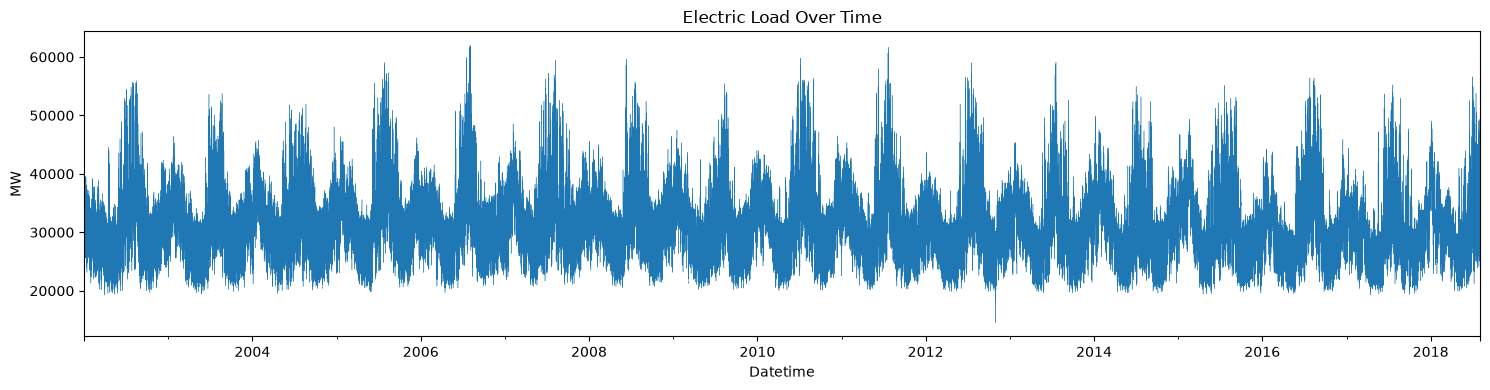

In [9]:
plt.figure(figsize=(15,4)); df['PJME_MW'].plot(linewidth=0.3)
plt.title('Electric Load Over Time'); 
plt.ylabel('MW'); 

plt.tight_layout(); 
plt.show()

### Daily, Weekly And Seasonal Profiles

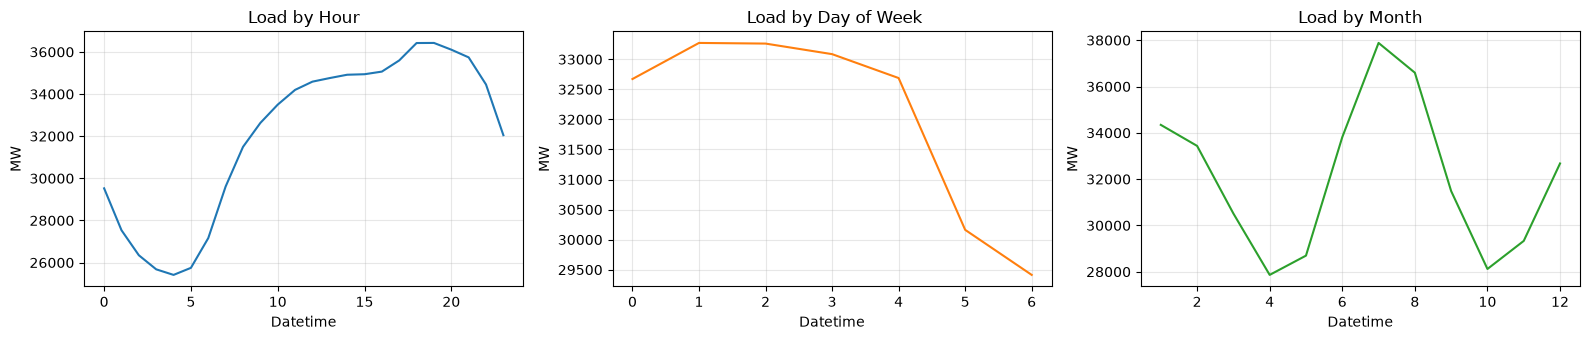

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
df.groupby(df.index.hour)['PJME_MW'].mean().plot(ax=ax[0], 
                                                 title='Load by Hour', color='tab:blue')
df.groupby(df.index.dayofweek)['PJME_MW'].mean().plot(ax=ax[1], 
                                                      title=' Load by Day of Week', color='tab:orange')
df.groupby(df.index.month)['PJME_MW'].mean().plot(ax=ax[2], 
                                                  title='Load by Month', color='tab:green')
for a in ax: a.set_ylabel('MW'); a.grid(alpha=0.3)

plt.tight_layout() 

plt.show()

#### Seasonal decomposition (last 365 days)

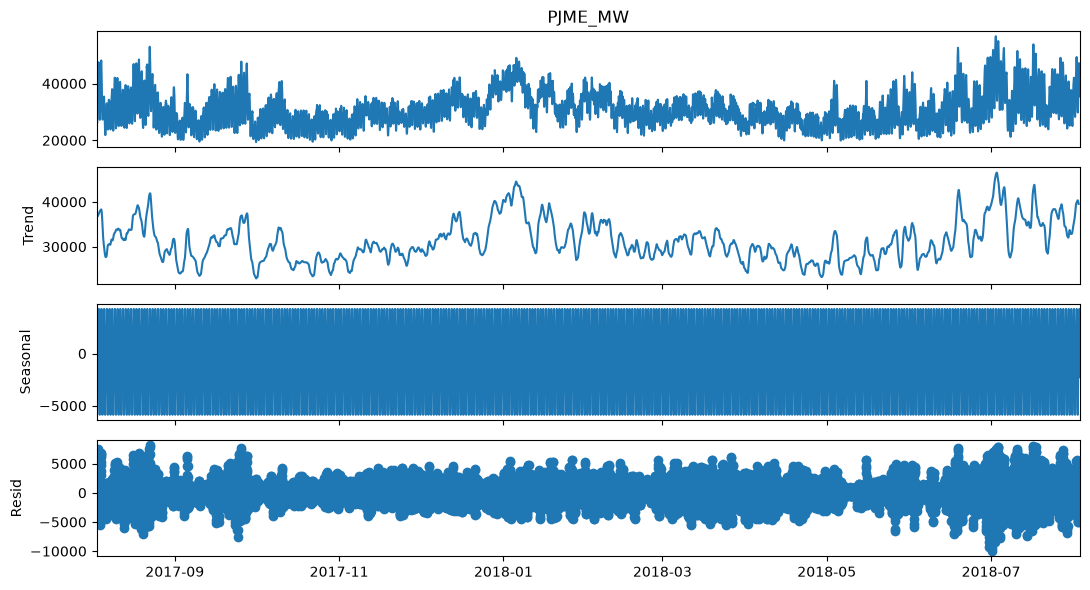

In [11]:
from statsmodels.tsa.seasonal import seasonal_decompose
cutoff = df.index.max() - pd.Timedelta('365D')
series = df.loc[df.index >= cutoff, 'PJME_MW'].interpolate('time')
dec = seasonal_decompose(series, model='additive', period=24)

fig = dec.plot() 
fig.set_size_inches(11, 6) 

plt.tight_layout() 
plt.show()

In [12]:
print(df.loc[df.index >= cutoff, 'PJME_MW'].isna().sum(), "NaNs in last 365 days")

1 NaNs in last 365 days


#### Feature correlations 

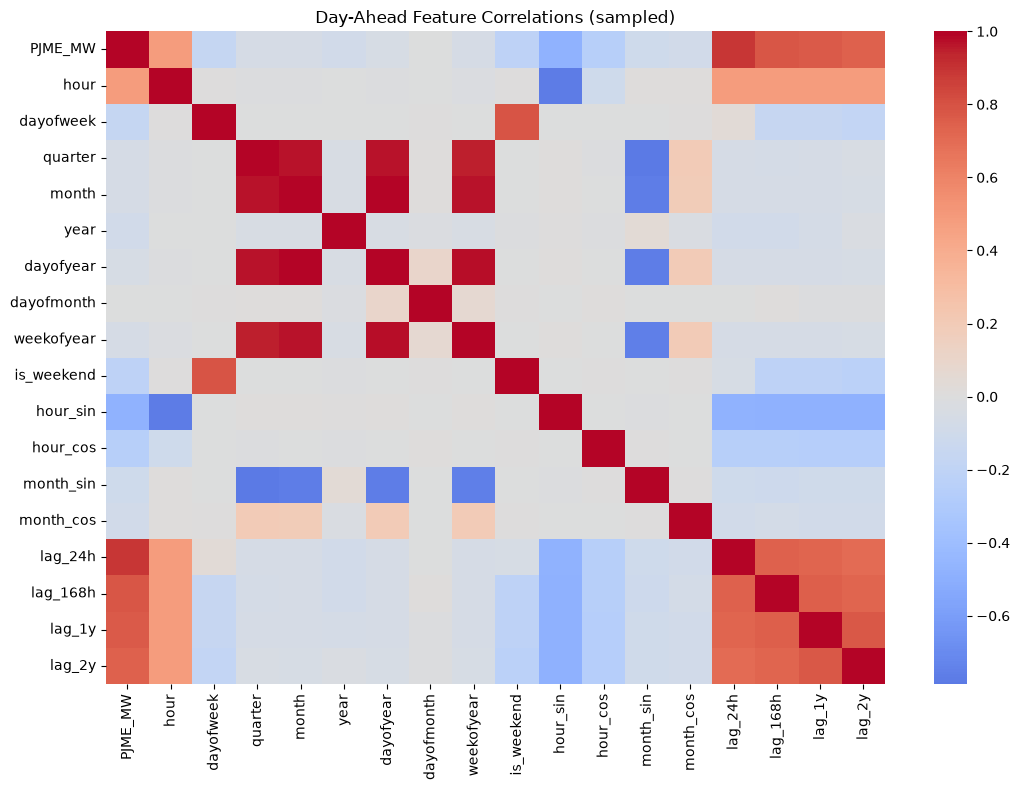

Modeling rows: 127826


In [13]:
feat = build_modeling_frame(df)
sample = feat[['PJME_MW'] + FEATURES_COLS].dropna().sample(20000, random_state=42)
plt.figure(figsize=(11, 8))
sns.heatmap(sample.corr(numeric_only=True), cmap='coolwarm', center=0)
plt.title('Day-Ahead Feature Correlations (sampled)')

plt.tight_layout()
plt.show()


print('Modeling rows:', len(feat))

# 4. Forecasting 

A 60-day test set is held untouched; the prior 30 days tune early stopping. Features exclude prior-hour load and rolling statistics, so everything is observable when a next-day schedule is committed

In [14]:
data = build_modeling_frame(df)

test_start = data.index.max() - pd.Timedelta('60D')
validation_start = test_start - pd.Timedelta('30D')

fit_train = data[data.index <= validation_start]
validation = data[(data.index > validation_start) & (data.index <= test_start)]
test = data[data.index > test_start]

train = pd.concat([fit_train, validation])  # Cross-validation data only

print('Fit:', fit_train.shape[0], '| Validation:', validation.shape[0], '| Test:', test.shape[0])

Fit: 125666 | Validation: 720 | Test: 1440


#### Time-series cross-validation (5 Folds )

In [15]:
cv_scores = xgb_train_cv(train, FEATURES_COLS, n_splits=5)
print("Cross-validation scores:", cv_scores)

[Fold 1] RMSE: 3189.33 MAPE: 7.46%
[Fold 2] RMSE: 2031.14 MAPE: 5.55%
[Fold 3] RMSE: 1569.14 MAPE: 3.97%
[Fold 4] RMSE: 1798.94 MAPE: 4.94%
[Fold 5] RMSE: 3146.56 MAPE: 7.34%
[XGB] Mean RMSE: 2347.02 (+/- 686.15)
Cross-validation scores: [np.float64(3189.3298817447367), np.float64(2031.1399452921512), np.float64(1569.1355931674052), np.float64(1798.9401837672153), np.float64(3146.562390218174)]


#### Final fit & evaluation 

In [16]:
model, y_test, preds = xgb_train_final(fit_train, validation, test, FEATURES_COLS)

print(f'DAY-AHEAD TEST RMSE: {rmse(y_test, preds):,.1f} MW')
print(f'DAY-AHEAD TEST MAPE: {mape(y_test, preds):.2f} %')
forecast_demand = preds.clip(lower=0).rename('forecast_MW')

DAY-AHEAD TEST RMSE: 3,452.9 MW
DAY-AHEAD TEST MAPE: 7.59 %


#### Actual  Vs Predicted + Feature Importance 

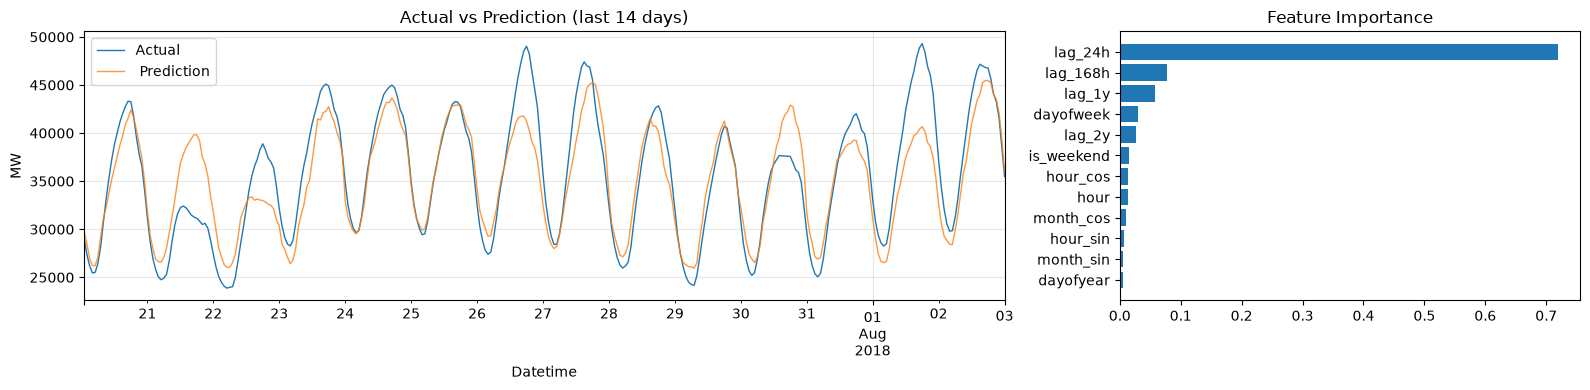

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={'width_ratios':[2,1]})
y_test.iloc[-24*14:].plot(ax=ax[0], label='Actual', linewidth=1)
preds.iloc[-24*14:].plot(ax=ax[0], label=' Prediction', linewidth=1, alpha=0.8)
ax[0].set_title('Actual vs Prediction (last 14 days)')
ax[0].set_ylabel('MW')
ax[0].legend() 
ax[0].grid(alpha=0.3)


fi = feature_importance(model, FEATURES_COLS).head(12).sort_values('importance')
ax[1].barh(fi['feature'], fi['importance'])
ax[1].set_title('Feature Importance')



plt.tight_layout()
plt.show()

# 5. Forecast-based Cost Simulation (Time-of-Use + Peak Shifting)

The tariff is peak 17:00–20:00, off-peak 00:00–05:00, shoulder otherwise. Load forecasts for the last 30 days are scaled to a single customer, and 20% of each day’s peak load is shifted into that day’s off-peak hours, keeping each day’s total energy unchanged

In [18]:
PEAK = list(range(17,21)); OFF = list(range(0,6))
BASE_P, PEAK_P, OFF_P = 50.0, 120.0, 25.0
SCALE = 0.001 

demand = forecast_demand.iloc[-24*30:] * SCALE
shifted = peak_shift(demand, PEAK, OFF, 0.20)

print('Forecast energy difference (per-day conservation):', round(demand.sum()-shifted.sum(), 2), 'MWh')
res = summarize_costs(demand, shifted, PEAK, OFF, BASE_P, PEAK_P, OFF_P)
res['Value'] = res['Value'].map(lambda v: f'{v:,.2f}')
res

Forecast energy difference (per-day conservation): 0.0 MWh


,Metric,Value
0,Predicted Energy (MWh),"25,870.72"
1,Base Cost ($),"1,512,098.33"
2,Scenario Cost ($),"1,416,385.80"
3,Savings ($),"95,712.53"
4,Savings (%),6.33


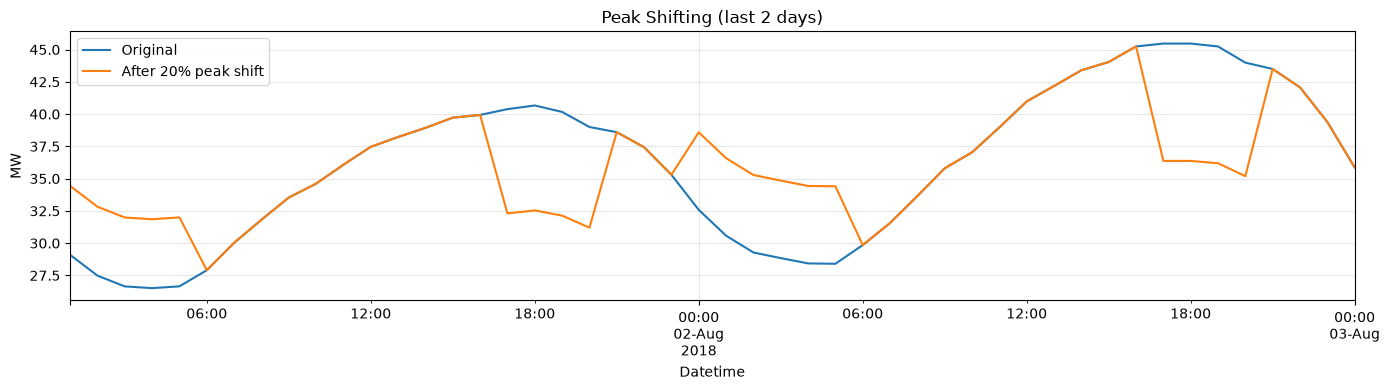

In [19]:
plt.figure(figsize=(14,4))
demand.iloc[-48:].plot(label='Original', linewidth=1.5)
shifted.iloc[-48:].plot(label='After 20% peak shift', linewidth=1.5)
plt.title('Peak Shifting (last 2 days)'); 
plt.ylabel('MW'); 
plt.legend(); 
plt.grid(alpha=0.3)


plt.tight_layout() 
plt.show()

# 6. Day-ahead Battery Scheduling Vs Perfect Foresight

A stylized fleet is sized at 30% of the actor's training-period peak (~18.6 MW / 74.4 MWh), where the actor represents 0.1% of PJME zone load. The battery schedule is optimized **day-ahead against the load forecast**, then that fixed schedule is applied to **actual** demand to compute realized cost - the battery cannot react to load it hasn't seen yet.

A second optimization runs directly on actual demand: an intentionally unattainable **perfect-foresight benchmark**. The gap between realized and perfect-foresight cost is the economic value lost to forecast error; realized savings as a fraction of ideal savings is the schedule's **capture rate**.

In [20]:
# --- Day-ahead schedule vs perfect foresight (actor scale, demand charge) ----
FLEET_SHARE   = 0.001    # actor = 0.1% of zone load
DEMAND_CHARGE = 20000 / 30   # $/MW on daily peak grid draw (~$20/kW-month)
ROUND_TRIP_EFFICIENCY=0.92

# Actor-scale demand — battery must be big relative to its host or demand never binds.
week_index = y_test.index
actual   = y_test.loc[week_index] * FLEET_SHARE
forecast = forecast_demand.loc[week_index] * FLEET_SHARE


prices = price_series(forecast.index, PEAK, OFF, BASE_P, PEAK_P, OFF_P)

pmax = fit_train["PJME_MW"].max() * FLEET_SHARE * 0.30      # 30% of actor's training-period peak 
cap  = 4 * pmax
print(f'Actor peak {actual.max():,.1f} MW → battery {pmax:,.1f} MW / {cap:,.1f} MWh')


planned_days = []
realized_days = []
perfect_days = []

for _, actual_day in actual.groupby(actual.index.normalize()):
    planned = optimize_battery(forecast.loc[actual_day.index], prices.loc[actual_day.index],
                               capacity_mwh=cap, power_max_mw=pmax,
                               demand_charge=DEMAND_CHARGE)
    planned_days.append(planned)
    realized_days.append(realize_schedule(actual_day, planned, capacity_mwh=cap,
                                          round_trip_efficiency=ROUND_TRIP_EFFICIENCY))
    perfect_days.append(optimize_battery(actual_day, prices.loc[actual_day.index],
                                         capacity_mwh=cap, power_max_mw=pmax, 
                                         round_trip_efficiency=ROUND_TRIP_EFFICIENCY,
                                         demand_charge=DEMAND_CHARGE))
rolling_plan = pd.concat(planned_days)
rolling_realized = pd.concat(realized_days)
perfect = pd.concat(perfect_days)


# ONE cost formula, used everywhere: energy + demand charge on peak draw.
def total_cost(grid):
    return float(sum(
        (grid.loc[day.index] * prices.loc[day.index]).sum()
                    + DEMAND_CHARGE * day.max()
                    for _, day in grid.groupby(grid.index.normalize())))

baseline_actual_cost   = total_cost(actual)                  # no battery
rolling_realized_cost = total_cost(rolling_realized.actual_grid)  # day-ahead schedule, real load
perfect_cost        = total_cost(perfect.grid)          # unattainable benchmark

rolling_realized_savings = baseline_actual_cost - rolling_realized_cost
perfect_savings           = baseline_actual_cost - perfect_cost

summary = pd.DataFrame({
    'Metric': [
        'Pre-test fleet power / energy', 
        'Baseline actual cost ($)',
        'Rolling day-ahead realized savings ($)', 
        'Perfect-foresight savings ($)',
        'Forecast-error opportunity gap ($)',
        'Capture rate (%)'],
    'Value': [
        f'{pmax:,.1f} MW / {cap:,.1f} MWh', 
        f"{baseline_actual_cost:,.0f}",
        f"{rolling_realized_savings:,.0f}", 
        f"{perfect_savings:,.0f}",
        f"{rolling_realized_cost - perfect_cost:,.0f}",
        f"{100 * rolling_realized_savings / perfect_savings:.1f}"]})
summary

Actor peak 56.6 MW → battery 18.6 MW / 74.4 MWh


,Metric,Value
0,Pre-test fleet power / energy,18.6 MW / 74.4 MWh
1,Baseline actual cost ($),"4,667,262"
2,Rolling day-ahead realized savings ($),"261,965"
3,Perfect-foresight savings ($),"349,356"
4,Forecast-error opportunity gap ($),"87,390"
5,Capture rate (%),75.0


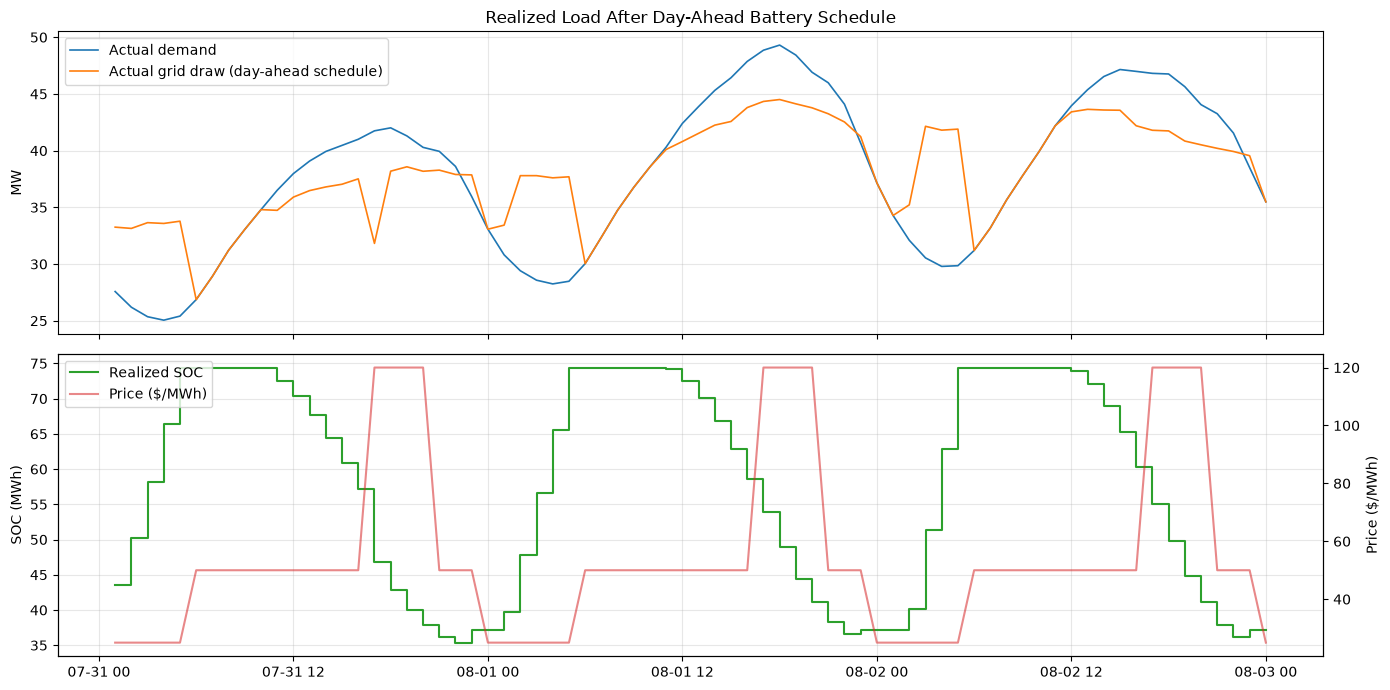

In [21]:
figure, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
plot_window = rolling_realized.iloc[-72:]

axes[0].plot(plot_window.index, plot_window['actual_demand'], label='Actual demand', linewidth=1.2)
axes[0].plot(plot_window.index, plot_window['actual_grid'], label='Actual grid draw (day-ahead schedule)', linewidth=1.2)
axes[0].set_ylabel('MW'); axes[0].set_title('Realized Load After Day-Ahead Battery Schedule')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].step(plot_window.index, plot_window['realized_soc'], where='post', color='tab:green', label='Realized SOC')
axes[1].set_ylabel('SOC (MWh)'); axes[1].grid(alpha=0.3)
ax_price = axes[1].twinx()                       # price on its own scale
ax_price.plot(plot_window.index, plot_window['price'], color='tab:red', alpha=.55, label='Price ($/MWh)')
ax_price.set_ylabel('Price ($/MWh)')

# merge legends from both twinned axes
l1, lab1 = axes[1].get_legend_handles_labels()
l2, lab2 = ax_price.get_legend_handles_labels()
axes[1].legend(l1 + l2, lab1 + lab2, loc='upper left')

plt.tight_layout(); 
plt.show()

In [22]:
print(f"Forecast   | RMSE {rmse(y_test, preds):,.1f} MW  |  MAPE {mape(y_test, preds):.2f}%")
print(f"Battery    | Realized savings  ${rolling_realized_savings:,.2f}")
print(f"Benchmark  | Perfect-foresight ${perfect_savings:,.2f}")
print(f"Gap        | ${perfect_savings - rolling_realized_savings:,.2f}")
print(f"Capture    | {100*rolling_realized_savings/perfect_savings:.1f}%")

Forecast   | RMSE 3,452.9 MW  |  MAPE 7.59%
Battery    | Realized savings  $261,965.40
Benchmark  | Perfect-foresight $349,355.69
Gap        | $87,390.29
Capture    | 75.0%


---
## Summary

   | Stage | Metric | Value |
   |---|---|---|
   | Forecast (day-ahead) | Untouched 60-day test RMSE / MAPE | `3,452.9 MW` / `7.59%` |
   | Battery | Rolling day-ahead realized savings (60 days) | `$261,965` |
   | Benchmark | Perfect-foresight savings (60 days) | `$349,356` |
   | Forecast-error gap | Perfect-foresight − realized | `$87,390` |
   | **Capture rate** | Realized ÷ perfect-foresight savings | **`75.0%`** |

**Day-ahead forecast → committed schedule → realized cost**, compared
against a transparent perfect-foresight upper bound. The capture rate
quantifies how much of the theoretically available battery savings a
real forecast actually delivers.